# 15 · Evaluación: comparación de modelos, test e interpretación

Este notebook reúne las predicciones de los baselines (notebook 11) y de los modelos (notebooks 12 a 14), selecciona
el modelo final con validación, lo evalúa una única vez en test y comprueba la hipótesis. Después analiza el error del
modelo final por segmentos, su sobreajuste, su evolución mes a mes y su interpretación con SHAP.

1. Criterio de la hipótesis
2. Predicciones de validación
3. Comparativa en validación
4. Skill score en validación
5. Selección del modelo
6. Test y comprobación de la hipótesis
7. Análisis por segmentos (test)
8. Sobreajuste del modelo final
9. Evolución mensual del error
10. Interpretabilidad (SHAP)

- **Entrada:** `data/modeling/` y `data/predictions/`
- **Salida:** tablas en `results/tables/` y figuras en `results/figures/`

In [97]:
import sys
from pathlib import Path

# Raíz del repositorio (la carpeta que contiene src/), para poder importar src
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from lightgbm import LGBMRegressor

from src.modelado import (CONFIG_LGBM_FINAL, OBJETIVO, VARIABLES, ajustar_y_predecir, bloques_evaluacion,
                          cargar_datos_modelado, metricas, preparar_para_lightgbm, rellenar_desconocidas)
from src.rutas import FIGURES, PREDICTIONS, TABLES

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

## 1. Criterio de la hipótesis

**Hipótesis:** el modelo mejora la planificación actual del ERP en al menos un **20 %**.

**Criterio cuantitativo:** el modelo seleccionado obtiene un skill score de MAE **≥ 20 %** respecto a **B0**
(ratio = 1, planificación del ERP), calculado como `1 − MAE_modelo / MAE_B0`. Tanto se calcula en validación, con la media de los 3 folds (para seleccionar), y en test.

**Comparaciones complementarias** (no forman parte de la hipótesis): el skill score frente a B1, B2-familia y
B2-máquina se usa para valorar la efectividad del modelo:
- frente a B1: ¿aporta más que corregir el sesgo global?
- frente a B2: ¿aporta más que una tabla de consulta por grupo?

## 2. Predicciones de validación

In [98]:
df_split, MESES_VALIDACION = cargar_datos_modelado()

b0    = pd.read_parquet(PREDICTIONS / "b0.parquet")
b1    = pd.read_parquet(PREDICTIONS / "b1.parquet")
b2    = pd.read_parquet(PREDICTIONS / "b2.parquet")
ridge = pd.read_parquet(PREDICTIONS / "ridge_valid.parquet")
rf    = pd.read_parquet(PREDICTIONS / "rf_valid.parquet")
lgbm  = pd.read_parquet(PREDICTIONS / "lgbm_valid.parquet")

for nombre, d in {"b0": b0, "b1": b1, "b2": b2, "ridge": ridge, "rf": rf, "lgbm": lgbm}.items():
    print(f"{nombre:6} | {d.shape} | {list(d.columns)}")

b0     | (14146, 5) | ['IDMOTask', 'split', 'mes_orden', 'ratio', 'pred_B0']
b1     | (14146, 6) | ['IDMOTask', 'split', 'mes_orden', 'ratio', 'pred_B1_mediana', 'pred_B1_media']
b2     | (14146, 8) | ['IDMOTask', 'split', 'mes_orden', 'ratio', 'pred_B2_familia_mediana', 'pred_B2_familia_media', 'pred_B2_maquina_mediana', 'pred_B2_maquina_media']
ridge  | (2871, 5) | ['IDMOTask', 'mes_orden', 'ratio', 'pred_ridge_ratio', 'pred_ridge_log']
rf     | (2871, 5) | ['IDMOTask', 'mes_orden', 'ratio', 'pred_rf_ratio', 'pred_rf_log']
lgbm   | (2871, 5) | ['IDMOTask', 'mes_orden', 'ratio', 'pred_lgbm_ratio', 'pred_lgbm_log']


Las predicciones de B0, B1 y B2 contienen todas las fases del dataset; en B1 y B2, las fases que solo se usan para
entrenar tienen NaN. Las de los modelos contienen solo las fases de validación.

Se unen todas las predicciones de validación en una tabla, fase a fase:

In [99]:
valid = ridge[["IDMOTask", "mes_orden", "ratio", "pred_ridge_ratio", "pred_ridge_log"]]
for d in [rf, lgbm, b0, b1, b2]:
    cols_pred = [c for c in d.columns if c.startswith("pred_")]
    valid = valid.merge(d[["IDMOTask"] + cols_pred], on="IDMOTask", how="left")

print(valid.shape, "| nulos:", valid.isna().sum().sum())
valid.filter(like="pred_").describe().loc[["mean", "50%"]].round(2)

(2871, 16) | nulos: 0


,pred_ridge_ratio,pred_ridge_log,pred_rf_ratio,pred_rf_log,pred_lgbm_ratio,pred_lgbm_log,pred_B0,pred_B1_mediana,pred_B1_media,pred_B2_familia_mediana,pred_B2_familia_media,pred_B2_maquina_mediana,pred_B2_maquina_media
mean,1.88,1.57,1.87,1.58,1.87,1.58,1.0,1.46,1.87,1.47,1.88,1.50,1.89
50%,1.87,1.52,1.81,1.53,1.77,1.54,1.0,1.45,1.87,1.56,1.98,1.54,1.95


## 3. Comparativa en validación

En la tabla de MAE los baselines B1 y B2 usan la mediana; en la de RMSE, la media. Cada métrica se compara con la
versión del baseline que la minimiza.

> Para los baselines, el MAE se calcula comparando la predicción basada en la **mediana** con el ratio real, y el
> RMSE comparando la predicción basada en la **media** con el ratio real.

In [100]:
MODELOS = ["pred_ridge_ratio", "pred_ridge_log", "pred_rf_ratio", "pred_rf_log", "pred_lgbm_ratio", "pred_lgbm_log"]
BASELINES = ["B0", "B1", "B2-familia", "B2-máquina"]

# Cada métrica con la versión de baseline que la minimiza
cols_MAE  = MODELOS + ["pred_B0", "pred_B1_mediana", "pred_B2_familia_mediana", "pred_B2_maquina_mediana"]
cols_RMSE = MODELOS + ["pred_B0", "pred_B1_media",   "pred_B2_familia_media",   "pred_B2_maquina_media"]

nombres = {"pred_B0": "B0",
           "pred_B1_mediana": "B1", "pred_B1_media": "B1",
           "pred_B2_familia_mediana": "B2-familia", "pred_B2_familia_media": "B2-familia",
           "pred_B2_maquina_mediana": "B2-máquina", "pred_B2_maquina_media": "B2-máquina"}

filas = []
for mes in MESES_VALIDACION:
    datos = valid[valid["mes_orden"] == mes]
    for col in sorted(set(cols_MAE + cols_RMSE)):
        m = metricas(datos["ratio"], datos[col])
        filas.append({"mes": mes, "prediccion": col, "MAE": m["MAE"], "RMSE": m["RMSE"]})
comparativa = pd.DataFrame(filas)

tabla_MAE = comparativa.pivot(index="prediccion", columns="mes", values="MAE")
tabla_RMSE = comparativa.pivot(index="prediccion", columns="mes", values="RMSE")
tabla_MAE["media_folds"] = tabla_MAE.mean(axis=1)
tabla_RMSE["media_folds"] = tabla_RMSE.mean(axis=1)

tabla_MAE_final = tabla_MAE.loc[cols_MAE].rename(index=nombres).sort_values("media_folds")
tabla_RMSE_final = tabla_RMSE.loc[cols_RMSE].rename(index=nombres).sort_values("media_folds")
tabla_MAE_final.index.name = "prediccion_MAE"
tabla_RMSE_final.index.name = "prediccion_RMSE"

tabla_MAE_final.round(3).to_csv(TABLES / "validacion_MAE.csv")
tabla_RMSE_final.round(3).to_csv(TABLES / "validacion_RMSE.csv")
display(tabla_MAE_final.round(3))
display(tabla_RMSE_final.round(3))

mes,2026-02,2026-03,2026-04,media_folds
prediccion_MAE,,,,
pred_lgbm_log,0.897,0.800,0.806,0.834
pred_rf_log,0.904,0.819,0.802,0.842
pred_lgbm_ratio,0.901,0.813,0.822,0.845
pred_ridge_log,0.918,0.812,0.816,0.849
pred_rf_ratio,0.913,0.832,0.820,0.855
pred_ridge_ratio,0.935,0.831,0.837,0.868
B2-máquina,0.978,0.890,0.922,0.930
B2-familia,0.988,0.900,0.937,0.942
B1,1.021,0.928,0.967,0.972


mes,2026-02,2026-03,2026-04,media_folds
prediccion_RMSE,,,,
pred_lgbm_ratio,1.281,1.187,1.181,1.216
pred_rf_ratio,1.302,1.214,1.179,1.231
pred_ridge_ratio,1.310,1.203,1.192,1.235
pred_lgbm_log,1.359,1.256,1.254,1.289
pred_rf_log,1.376,1.279,1.247,1.301
pred_ridge_log,1.380,1.266,1.261,1.302
B2-máquina,1.409,1.318,1.327,1.351
B2-familia,1.436,1.335,1.350,1.374
B1,1.474,1.373,1.394,1.414


Los MAE de los baselines coinciden con los obtenidos en el notebook 11, por lo que la unión de predicciones es
correcta.

**MAE** (baselines con mediana):

- Los 6 modelos obtienen menor MAE que todos los baselines en los 3 folds, incluido B2-máquina, el más exigente.
- Para cada modelo, la versión **log(ratio)** tiene menor MAE que la versión ratio en los 3 folds.
- El menor MAE medio es el de **LightGBM-log**, seguido de RF-log y LightGBM-ratio. El orden entre modelos no se mantiene en todos los folds: en abril RF-log queda por delante de LightGBM-log.

**RMSE** (baselines con media):

- Los 6 modelos obtienen menor RMSE que todos los baselines en los 3 folds (B2-máquina).
- Para cada modelo, la versión **ratio** tiene menor RMSE que la versión log en los 3 folds.
- El menor RMSE medio es el de **LightGBM-ratio**.

**En todos los casos** febrero es el fold con mayor error.

## 4. Skill score en validación

skill = 1 − error_modelo / error_baseline

In [101]:
def tabla_skill(tabla):
    """Skill score de cada modelo frente a cada baseline, con la media de los folds."""
    modelos_t = tabla.drop(index=BASELINES)["media_folds"]
    resultado = pd.DataFrame()
    for b in BASELINES:
        resultado[f"vs {b}"] = 1 - modelos_t / tabla.loc[b, "media_folds"]
    return resultado


skill_MAE = tabla_skill(tabla_MAE_final)
skill_RMSE = tabla_skill(tabla_RMSE_final)
(skill_MAE * 100).round(1).to_csv(TABLES / "skill_validacion_MAE.csv")

print("Skill score MAE (%)")
display((skill_MAE * 100).sort_values("vs B2-máquina", ascending=False).round(1))
print("Skill score RMSE (%)")
display((skill_RMSE * 100).sort_values("vs B2-máquina", ascending=False).round(1))

Skill score MAE (%)


,vs B0,vs B1,vs B2-familia,vs B2-máquina
prediccion_MAE,,,,
pred_lgbm_log,24.5,14.2,11.4,10.3
pred_rf_log,23.9,13.4,10.6,9.5
pred_lgbm_ratio,23.6,13.0,10.2,9.1
pred_ridge_log,23.3,12.7,9.9,8.7
pred_rf_ratio,22.7,12.1,9.2,8.1
pred_ridge_ratio,21.5,10.7,7.9,6.7


Skill score RMSE (%)


,vs B0,vs B1,vs B2-familia,vs B2-máquina
prediccion_RMSE,,,,
pred_lgbm_ratio,28.9,14.0,11.5,10.0
pred_rf_ratio,28.0,12.9,10.4,8.9
pred_ridge_ratio,27.8,12.7,10.1,8.6
pred_lgbm_log,24.6,8.8,6.1,4.6
pred_rf_log,24.0,8.0,5.3,3.7
pred_ridge_log,23.9,7.9,5.2,3.6


### Conclusiones de la comparativa en validación

**Comparativa de errores**

- Los 6 modelos obtienen menor MAE y menor RMSE que todos los baselines en los 3 folds, incluido B2-máquina, el
  baseline más exigente.
- En MAE, la versión **log(ratio)** es mejor que la versión ratio para los tres modelos y en los tres folds. En RMSE
  ocurre lo contrario: la versión **ratio** es mejor en todos los casos.
- El menor MAE medio lo obtiene **LightGBM-log** y el menor RMSE medio, **LightGBM-ratio**.

**Skill score (MAE)**

- Frente a B0, todos los modelos superan el umbral del 20 % fijado en la hipótesis con la media de los 3 folds.
- Frente a B1, B2-familia y B2-máquina la mejora es menor, pero positiva en todos los casos.

**Skill score (RMSE)**

- Las versiones ratio obtienen mejores resultados que las de log(ratio).

Antes de seleccionar el modelo que pasa a test, se comprueba la estabilidad del skill fold a fold.

**Métrica principal y complementaria.** Se prioriza el MAE porque el objetivo es mejorar la planificación de la fase
habitual: el MAE pondera cada error en proporción a su tamaño y está alineado con la mediana, por lo que no se ve
dominado por las fases con desviaciones extremas. El RMSE, que penaliza más los errores grandes, se reporta como
complemento: en él las versiones ratio superan a las log en todos los modelos y folds. La elección de log(ratio)
supone por tanto aceptar un peor comportamiento en las desviaciones grandes a cambio de un menor error en la fase
típica.

### Evolución del skill de MAE fold a fold

In [102]:
for b in BASELINES:
    skill_fold = 1 - tabla_MAE_final.drop(index=BASELINES) / tabla_MAE_final.loc[b]
    print(f"Skill score MAE (%) vs {b}")
    display((skill_fold * 100).sort_values("media_folds", ascending=False).round(1))

Skill score MAE (%) vs B0


mes,2026-02,2026-03,2026-04,media_folds
prediccion_MAE,,,,
pred_lgbm_log,21.3,26.3,26.2,24.5
pred_rf_log,20.6,24.5,26.6,23.9
pred_lgbm_ratio,20.9,25.1,24.8,23.6
pred_ridge_log,19.4,25.2,25.3,23.3
pred_rf_ratio,19.9,23.4,24.9,22.7
pred_ridge_ratio,17.9,23.5,23.4,21.5


Skill score MAE (%) vs B1


mes,2026-02,2026-03,2026-04,media_folds
prediccion_MAE,,,,
pred_lgbm_log,12.1,13.8,16.6,14.2
pred_rf_log,11.4,11.7,17.1,13.4
pred_lgbm_ratio,11.7,12.4,15.0,13.0
pred_ridge_log,10.1,12.5,15.6,12.7
pred_rf_ratio,10.6,10.4,15.2,12.1
pred_ridge_ratio,8.4,10.5,13.4,10.7


Skill score MAE (%) vs B2-familia


mes,2026-02,2026-03,2026-04,media_folds
prediccion_MAE,,,,
pred_lgbm_log,9.2,11.1,14.0,11.4
pred_rf_log,8.5,8.9,14.5,10.6
pred_lgbm_ratio,8.8,9.6,12.3,10.2
pred_ridge_log,7.1,9.8,12.9,9.9
pred_rf_ratio,7.6,7.6,12.5,9.2
pred_ridge_ratio,5.4,7.7,10.7,7.9


Skill score MAE (%) vs B2-máquina


mes,2026-02,2026-03,2026-04,media_folds
prediccion_MAE,,,,
pred_lgbm_log,8.3,10.1,12.6,10.3
pred_rf_log,7.5,7.9,13.1,9.5
pred_lgbm_ratio,7.8,8.6,10.9,9.1
pred_ridge_log,6.1,8.7,11.5,8.7
pred_rf_ratio,6.6,6.5,11.1,8.1
pred_ridge_ratio,4.4,6.6,9.2,6.7


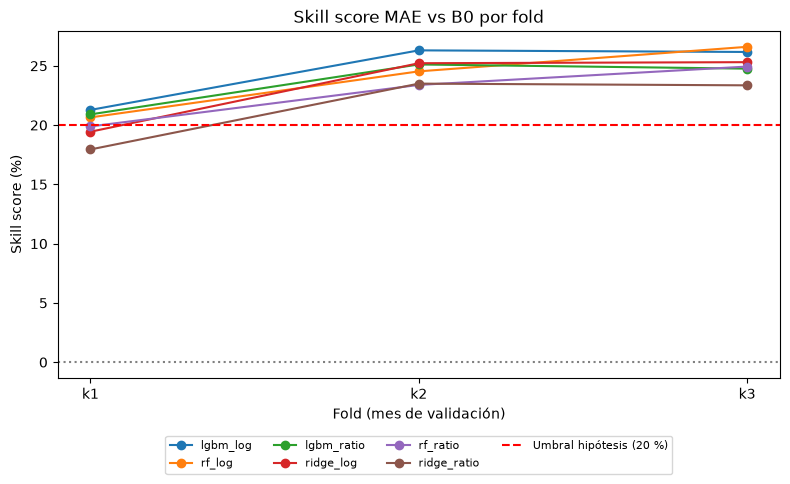

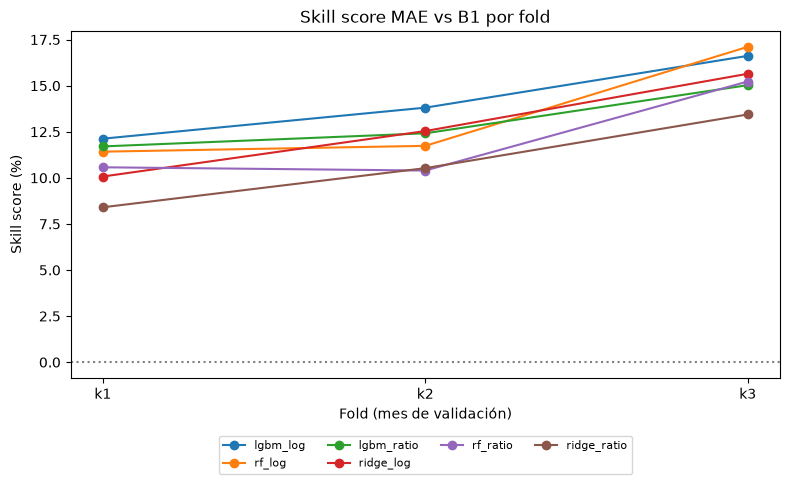

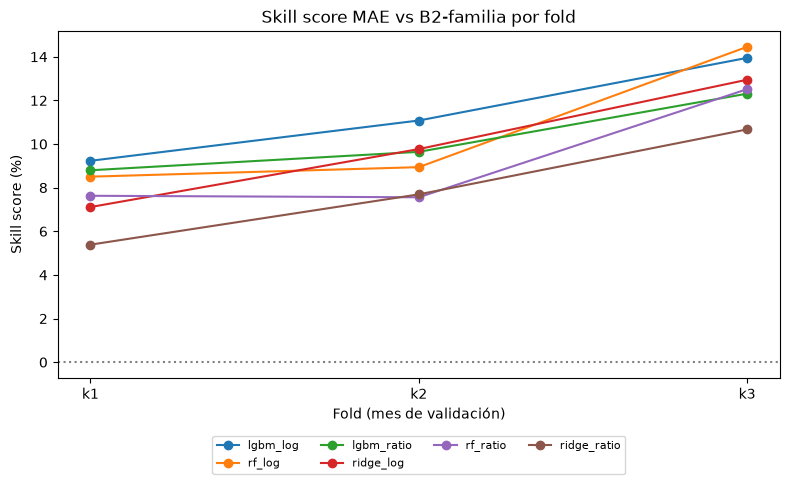

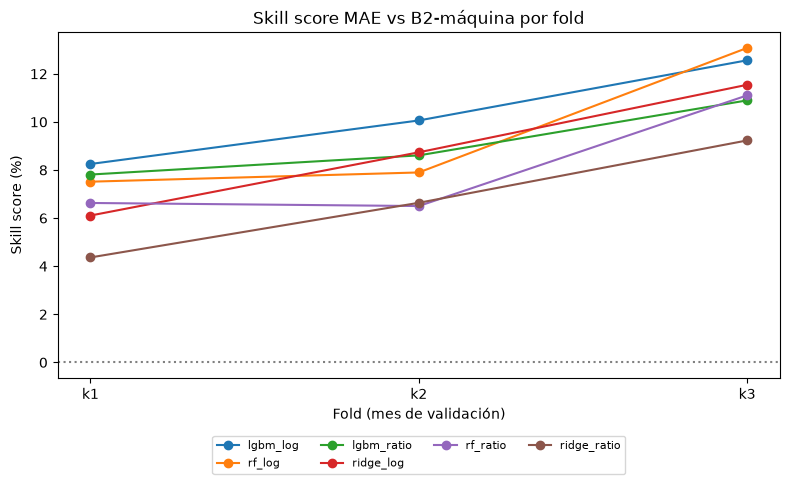

In [103]:
archivo = {"B0": "B0", "B1": "B1", "B2-familia": "B2_familia", "B2-máquina": "B2_maquina"}

for b in BASELINES:
    modelos_t = tabla_MAE_final.drop(index=BASELINES)[MESES_VALIDACION]
    skill_fold = (1 - modelos_t / tabla_MAE_final.loc[b, MESES_VALIDACION]) * 100

    fig, ax = plt.subplots(figsize=(8, 5))
    for modelo, fila in skill_fold.iterrows():
        ax.plot(["k1", "k2", "k3"], fila.values, marker="o", label=modelo.replace("pred_", ""))

    ax.axhline(0, color="grey", linestyle=":")
    if b == "B0":   # el umbral de la hipótesis solo aplica frente a B0
        ax.axhline(20, color="red", linestyle="--", label="Umbral hipótesis (20 %)")

    ax.set_title(f"Skill score MAE vs {b} por fold")
    ax.set_xlabel("Fold (mes de validación)")
    ax.set_ylabel("Skill score (%)")
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, fontsize=8)
    plt.tight_layout()
    plt.savefig(FIGURES / f"15_skill_por_fold_vs_{archivo[b]}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 5. Selección del modelo (con validación)

Se selecciona **LightGBM con objetivo log(ratio)** como modelo final:

- Obtiene el menor MAE medio en validación.
- El skill score de MAE frente a B0 supera el 20 % en los tres folds.
- Frente a B2-máquina, el baseline más exigente, reduce el MAE un 14,2 % de media.

Ridge-log, RF-ratio y Ridge-ratio cumplen el criterio con la media de los folds, pero no en febrero. En RMSE, las versiones log obtienen peores resultados que las versiones ratio; se asume este peor comportamiento en las desviaciones grandes a cambio de un menor error en la fase típica, coherente con la elección del MAE como métrica
principal.

## 6. Test y comprobación de la hipótesis

Los 6 modelos se reentrenaron con todo el conjunto de desarrollo (al final de cada notebooks `12` a `14`) y aquí se evalúan en test con fines comparativos.    
    
El modelo final seleccionado es LightGBM-log, esto se ha decidido con validación, no se modifica la elección en función de los resultados que presente test.

In [104]:
ridge_t = pd.read_parquet(PREDICTIONS / "ridge_test.parquet")
rf_t    = pd.read_parquet(PREDICTIONS / "rf_test.parquet")
lgbm_t  = pd.read_parquet(PREDICTIONS / "lgbm_test.parquet")

test_df = ridge_t[["IDMOTask", "ratio", "pred_ridge_ratio", "pred_ridge_log"]]
for d in [rf_t, lgbm_t, b0, b1, b2]:
    cols_pred = [c for c in d.columns if c.startswith("pred_")]
    test_df = test_df.merge(d[["IDMOTask"] + cols_pred], on="IDMOTask", how="left")

print(test_df.shape, "| nulos:", test_df.isna().sum().sum())

(2385, 15) | nulos: 0


### Error por modelo (baselines con mediana en MAE y con media en RMSE)

In [105]:
mae_test = pd.Series({nombres.get(c, c): metricas(test_df["ratio"], test_df[c])["MAE"] for c in cols_MAE})
rmse_test = pd.Series({nombres.get(c, c): metricas(test_df["ratio"], test_df[c])["RMSE"] for c in cols_RMSE})

test_metricas = pd.DataFrame({"MAE": mae_test, "RMSE": rmse_test}).sort_values("MAE")
test_metricas.index.name = "prediccion"
test_metricas.round(3).to_csv(TABLES / "test_metricas.csv")
test_metricas.round(3)

,MAE,RMSE
prediccion,,
pred_lgbm_log,0.786,1.175
pred_rf_log,0.790,1.186
pred_ridge_log,0.798,1.208
pred_rf_ratio,0.816,1.131
pred_lgbm_ratio,0.819,1.134
pred_ridge_ratio,0.836,1.156
B2-máquina,0.862,1.262
B2-familia,0.882,1.285
B1,0.904,1.316


Los modelos obtienen en test mejores resultados que en validación, tanto en MAE como en RMSE.

### Skill score en test (MAE)

In [106]:
skill_test = pd.DataFrame({f"vs {b}": (1 - mae_test[MODELOS] / mae_test[b]) * 100 for b in BASELINES})
skill_test = skill_test.sort_values("vs B0", ascending=False)
skill_test.index.name = "modelo"
skill_test.round(1).to_csv(TABLES / "skill_test_MAE.csv")
skill_test.round(1)

,vs B0,vs B1,vs B2-familia,vs B2-máquina
modelo,,,,
pred_lgbm_log,22.9,13.1,10.9,8.9
pred_rf_log,22.5,12.7,10.4,8.3
pred_ridge_log,21.7,11.7,9.5,7.4
pred_rf_ratio,19.9,9.8,7.4,5.3
pred_lgbm_ratio,19.6,9.4,7.1,4.9
pred_ridge_ratio,18.0,7.6,5.2,3.0


### Evaluación en test y comprobación de la hipótesis

Los MAE de los baselines en test coinciden con los obtenidos en el notebook 11.

**Hipótesis.** El modelo seleccionado con validación, **LightGBM-log**, obtiene en test un skill score de MAE del **23,0 % frente a B0**. Supera el umbral del 20 % fijado antes de ver resultados, por lo que **la hipótesis se confirma**.

**Comparativa en test:**

- Los 6 modelos obtienen menor MAE y menor RMSE que todos los baselines.
- En MAE, las versiones log superan a las ratio para los tres modelos, igual que en validación. Solo las versiones log
  superan el 20 % frente a B0. 
- En RMSE, las versiones ratio superan a las log para los tres modelos, igual que en validación.
- Frente a B2-máquina, el baseline más exigente, LightGBM-log reduce el MAE un 9,0 %.

**Respecto a validación**, el skill de LightGBM-log frente a B0 pasa de 24,7 % (media de folds) a 23,0 % en test, y
frente a B2-máquina de 10,5 % a 9,0 %.

### ¿Son los meses de test más fáciles?

El error baja en test para los modelos y para los baselines, también para B0, que no aprende nada. Este hecho sugiere que los meses de test son algo "más fáciles" de predecir: menos dispersión en el ratio. Para comprobarlo, se compara la dispersión del ratio en los bloques de validación y en test:

In [107]:
filas = []
for bloque, _, d in bloques_evaluacion(df_split, MESES_VALIDACION):
    r = d["ratio"]
    filas.append({"bloque": bloque, "n": len(d),
                  "media": r.mean(), "mediana": r.median(),
                  "desv_tipica": r.std(), "IQR": r.quantile(0.75) - r.quantile(0.25),
                  "MAE_B0": (1 - r).abs().mean()})
pd.DataFrame(filas).round(3)

,bloque,n,media,mediana,desv_tipica,IQR,MAE_B0
0,valid 2026-02,915,2.008,1.539,1.467,1.528,1.140
1,valid 2026-03,993,1.959,1.584,1.371,1.276,1.086
2,valid 2026-04,963,1.940,1.533,1.394,1.469,1.092
3,test,2385,1.883,1.489,1.317,1.349,1.019


En test el ratio tiene la menor desviación típica de los cuatro bloques, y también la menor media y mediana; el rango intercuartílico queda dentro del de los folds. La dispersión en test es algo menor, en línea con que el error de B0 sea también el menor en test.

## 7. Análisis por segmentos (test)

Se analiza el error del modelo seleccionado (LightGBM-log) frente a los baselines en distintos grupos de fases del
test.

In [108]:
vars_seg = ["IDMOTask", "Familia Maquinas", "CodigoMaquina", "TipoFase", "TiempoPrevisto", "maquina_no_vista"]
cols_pred = ["pred_lgbm_log", "pred_B0", "pred_B1_mediana", "pred_B2_familia_mediana", "pred_B2_maquina_mediana"]

seg = test_df[["IDMOTask", "ratio"] + cols_pred].merge(df_split[vars_seg], on="IDMOTask", how="left")

# Error absoluto de cada fase
seg["err_modelo"] = (seg["pred_lgbm_log"] - seg["ratio"]).abs()
seg["err_B0"]     = (seg["pred_B0"] - seg["ratio"]).abs()
seg["err_B1"]     = (seg["pred_B1_mediana"] - seg["ratio"]).abs()
seg["err_B2_fam"] = (seg["pred_B2_familia_mediana"] - seg["ratio"]).abs()
seg["err_B2_maq"] = (seg["pred_B2_maquina_mediana"] - seg["ratio"]).abs()

print(seg.shape, "| nulos:", seg.isna().sum().sum())


def tabla_segmento(columna, extra=None):
    """MAE del modelo y de los baselines por grupo, y skill score del modelo frente a cada baseline."""
    agregados = dict(n=("ratio", "size"), **(extra or {}),
                     MAE_modelo=("err_modelo", "mean"), MAE_B0=("err_B0", "mean"), MAE_B1=("err_B1", "mean"),
                     MAE_B2_fam=("err_B2_fam", "mean"), MAE_B2_maq=("err_B2_maq", "mean"))
    tabla = seg.groupby(columna, observed=True).agg(**agregados)
    for b in ["B0", "B1", "B2_fam", "B2_maq"]:
        tabla[f"skill_vs_{b}"] = (1 - tabla["MAE_modelo"] / tabla[f"MAE_{b}"]) * 100
    return tabla

(2385, 17) | nulos: 0


### Error por familia de máquina

In [109]:
tabla_fam = tabla_segmento("Familia Maquinas").sort_values("n", ascending=False)
tabla_fam.round(3).to_csv(TABLES / "test_por_familia.csv")
tabla_fam.round(3)

,n,MAE_modelo,MAE_B0,MAE_B1,MAE_B2_fam,MAE_B2_maq,skill_vs_B0,skill_vs_B1,skill_vs_B2_fam,skill_vs_B2_maq
Familia Maquinas,,,,,,,,,,
TPU,701,0.857,1.246,1.073,1.051,0.985,31.182,20.124,18.435,12.999
MTP,560,0.929,1.144,0.965,0.956,0.954,18.799,3.708,2.804,2.620
CV,414,0.774,1.034,0.899,0.897,0.895,25.129,13.855,13.716,13.509
TCN,241,0.472,0.488,0.539,0.473,0.472,3.236,12.348,0.188,-0.074
CH,170,0.527,0.559,0.673,0.580,0.586,5.617,21.619,9.000,10.077
C5,133,0.901,1.201,1.005,1.041,1.040,24.956,10.298,13.401,13.362
CV-ALU,71,0.524,0.575,0.669,0.572,0.572,8.938,21.661,8.468,8.380
CON,53,0.890,0.867,0.892,0.843,0.849,-2.646,0.292,-5.500,-4.818
FLEX,42,0.571,0.683,0.461,0.540,0.532,16.421,-23.675,-5.612,-7.291


Las familias TPU, MTP y CV concentran el mayor número de las fases de test.

- **Mayor mejora frente a B0:** TPU (31%), C5 (alrededor 25%) y CV (alrededor 25%), familias en las que el error del ERP es elevado (MAE_B0 > 1).
- **Menor mejora:** TCN (3%), CH (5%) y CV-ALU (9%). Son las familias con menor error del ERP, por lo que el margen de mejora se muestra reducido.
- MTP, la **segunda familia** en volumen, queda por debajo del 20 % frente a B0 (18%) y apenas mejora a B2-máquina (2%).
- CON (53 fases) obtiene **skill negativo** frente a B0 y B2, y **FLEX** (42 fases) frente a B2. Dado el tamaño reducido de estos grupos, estos resultados se interpretan con cautela.
- En TCN, CH y CV-ALU, B1 obtiene mayor error que B0: la corrección global del sesgo (≈ 1,47) desplaza al alza familias cuyo ratio típico está próximo a 1. En estas familias el modelo mejora claramente a B1 (12,8–22,8 %), aunque su mejora frente a B0 sea reducida.
- En FLEX (42 fases), B1 obtiene el menor error de todas las referencias, inferior también al del modelo.


### Máquinas no vistas en desarrollo

In [110]:
seg["grupo_maquina"] = np.where(seg["maquina_no_vista"],
                                seg["CodigoMaquina"].astype(str) + " (no vista)",
                                "Resto")
tabla_segmento("grupo_maquina").round(3)

,n,MAE_modelo,MAE_B0,MAE_B1,MAE_B2_fam,MAE_B2_maq,skill_vs_B0,skill_vs_B1,skill_vs_B2_fam,skill_vs_B2_maq
grupo_maquina,,,,,,,,,,
CM18 (no vista),1,0.741,0.142,0.329,0.208,0.329,-423.094,-125.671,-256.135,-125.671
CM19 (no vista),36,1.038,1.471,1.190,1.180,1.190,29.412,12.775,12.021,12.775
Resto,2348,0.782,1.012,0.900,0.877,0.857,22.782,13.167,10.902,8.789


In [111]:
familias_no_vistas = (df_split.loc[df_split["maquina_no_vista"], ["CodigoMaquina", "Familia Maquinas"]].drop_duplicates())

for maquina, familia in familias_no_vistas.itertuples(index=False):
    print(f"La máquina {maquina} pertenece a la familia: {familia}")

La máquina CM19 pertenece a la familia: CV
La máquina CM18 pertenece a la familia: C5


**CM19** es una máquina de la familia **CV** incorporada en mayo de 2026: aparece únicamente en test (36 fases) y no
existe en desarrollo. En estas fases B2-máquina recurre al fallback (constante de B1), lo que se confirma en la tabla
(MAE_B1 = MAE_B2_maq = 1,190).

- CM19 es un grupo más difícil que el resto: el ERP obtiene un MAE de 1,471 (resto: 1,013; familia CV: 1,047) y el
  modelo de 1,029 (resto: 0,782).
- El modelo reduce el MAE del ERP un 30,1 % en CM19 (resto: 22,8 %) y mejora a B2-familia un 12,8 % (resto: 11,0 %).

El modelo mantiene su mejora frente a todas las referencias en una máquina que no ha visto durante el entrenamiento,
apoyándose en variables conocidas como la familia, el tipo de fase o el tiempo previsto. CV es una de las familias con
más fases en desarrollo, lo que probablemente favorece este resultado; con máquinas nuevas de familias poco
representadas el comportamiento podría ser distinto. Dado el tamaño reducido del grupo (36 fases), el resultado se
considera orientativo.

Por otro lado la máquina **CM18** solo cuenta con una única instancia en todo el conjunto de datos, no pueden sacarse conclusiones la respecto.

### Error por duración de la fase

La duración se mide con el `TiempoPrevisto` por el ERP. Es mejor emplear este y no el real, porque es lo que se
conoce antes de producir.

In [112]:
# Tramos de duración: 5 grupos con el mismo número de fases
seg["tramo_duracion"] = pd.qcut(seg["TiempoPrevisto"], q=5)

tabla_dur = tabla_segmento("tramo_duracion", extra={"ratio_med": ("ratio", "median")})
tabla_dur.round(3).to_csv(TABLES / "test_por_duracion.csv")
tabla_dur.round(3)

,n,ratio_med,MAE_modelo,MAE_B0,MAE_B1,MAE_B2_fam,MAE_B2_maq,skill_vs_B0,skill_vs_B1,skill_vs_B2_fam,skill_vs_B2_maq
tramo_duracion,,,,,,,,,,,
"(4.999, 16.0]",509,2.213,1.179,1.681,1.399,1.336,1.292,29.873,15.707,11.752,8.744
"(16.0, 32.0]",459,1.694,0.901,1.183,1.002,0.976,0.968,23.785,10.012,7.643,6.882
"(32.0, 70.0]",486,1.485,0.769,0.990,0.886,0.885,0.873,22.350,13.225,13.122,11.929
"(70.0, 111.0]",457,1.316,0.603,0.695,0.652,0.682,0.645,13.201,7.565,11.624,6.511
"(111.0, 974.0]",474,1.139,0.444,0.491,0.541,0.491,0.495,9.582,17.943,9.589,10.252


Las fases se agrupan en cinco tramos de tamaño similar (quintiles) según el tiempo previsto por el ERP.

- La mediana del ratio disminuye de forma continua con la duración Esto es algo que ya se vio al estudiar el ratio. Lo que confirma en test que las fases cortas presentan mayores desviaciones relativas. 
- El error de todos los modelos y baselines disminuye con la duración.
- El skill score frente a B0 decrece con la duración: Supera el 20 % en las fases de hasta 70 minutos.
- Frente a B2 la mejora es positiva en todos los tramos.
- En el tramo más largo, B1 obtiene mayor error que B0, ya que la corrección global del sesgo sobreestima fases cuyo ratio típico está próximo a 1.

El modelo aporta la mayor mejora relativa en las fases cortas, donde el ERP infraestima más el tiempo real. Al estar medido en escala ratio, este análisis no refleja el impacto en tiempo absoluto, que se evalúa a continuación con el error en minutos.

### Error en minutos

Pasar de ratio a minutos es directo:

    tiempo real      = ratio × TiempoPrevisto
    tiempo inferido  = ratio_inferido × TiempoPrevisto

    error en minutos = |ratio_inferido − ratio| × TiempoPrevisto

El error en minutos es el error en ratio multiplicado por la duración prevista de la fase, por lo que las fases largas
pesan mucho más en minutos que en ratio.

In [113]:
metodos = {
    "LightGBM log(ratio)":   "pred_lgbm_log",
    "B0: ERP (ratio = 1)":   "pred_B0",
    "B1: mediana global":    "pred_B1_mediana",
    "B2: mediana familia":   "pred_B2_familia_mediana",
    "B2: mediana máquina":   "pred_B2_maquina_mediana",
}

real_min = seg["ratio"] * seg["TiempoPrevisto"]          # tiempo real de cada fase, en minutos
filas = []
for nombre, col in metodos.items():
    pred_min = seg[col] * seg["TiempoPrevisto"]          # tiempo predicho, en minutos
    error_min = pred_min - real_min                      # con signo: > 0 se pasa, < 0 se queda corto
    filas.append({
        "método":                   nombre,
        "error medio (min)":        error_min.abs().mean(),
        "error mediano (min)":      error_min.abs().median(),
        "error sobre tiempo real (%)": error_min.abs().sum() / real_min.sum() * 100,
        "desvío de la carga total (%)": error_min.sum() / real_min.sum() * 100,
    })

tabla_min = pd.DataFrame(filas).set_index("método")
mae_modelo = tabla_min.loc["LightGBM log(ratio)", "error medio (min)"]
tabla_min["mejora del modelo (%)"] = (1 - mae_modelo / tabla_min["error medio (min)"]) * 100
tabla_min.loc["LightGBM log(ratio)", "mejora del modelo (%)"] = np.nan    # no se compara consigo mismo

tabla_min.round(1)

,error medio (min),error mediano (min),error sobre tiempo real (%),desvío de la carga total (%),mejora del modelo (%)
método,,,,,
LightGBM log(ratio),41.2,23.4,37.9,-11.4,NaN
B0: ERP (ratio = 1),49.7,27.8,45.6,-31.7,17.0
B1: mediana global,50.3,29.0,46.2,0.5,18.0
B2: mediana familia,47.9,26.5,44.0,-5.2,14.0
B2: mediana máquina,47.1,25.2,43.2,-6.0,12.4


En minutos, el modelo es el mejor método en todas las métricas fase a fase: reduce el error medio un 17 % frente al ERP (41,2 frente a 49,7 minutos) y un 12,5 % frente al mejor baseline, B2-máquina (47,1 minutos). Aun así, el error sigue siendo elevado: equivale al 38 % del tiempo real total.

El desvío de la carga total muestra otra cara del problema. Planificando con los tiempos teóricos del ERP, la carga total se infraestima un 31,7 %. El modelo reduce esa infraestimación a un 11,4 %, pero no la elimina: es el sesgo de retransformación de la versión log(ratio), que apunta a la fase típica y se queda corto en las fases con mayor desviación.

Los baselines B1 y B2 obtienen desvíos menores (0,5 % y entre −5 % y −6 %) por una compensación accidental: al no distinguir la duración de las fases, sobreestiman las fases largas, que acumulan muchos minutos, y subestiman las cortas. Un desvío cercano a cero no indica un buen método.

In [114]:
# Errores en minutos, con signo (> 0 se pasa, < 0 se queda corto), y tiempo real de cada fase
seg["real_min"] = seg["ratio"] * seg["TiempoPrevisto"]
for nombre, col in {"modelo": "pred_lgbm_log", "B0": "pred_B0", "B2_maq": "pred_B2_maquina_mediana"}.items():
    seg[f"e_{nombre}"] = (seg[col] - seg["ratio"]) * seg["TiempoPrevisto"]
    seg[f"abs_{nombre}"] = seg[f"e_{nombre}"].abs()

g = seg.groupby("tramo_duracion", observed=True)
tabla_min_dur = pd.DataFrame({
    "n":                        g.size(),
    "error medio modelo (min)": g["abs_modelo"].mean(),
    "error medio ERP (min)":    g["abs_B0"].mean(),
    "error medio B2-máq (min)": g["abs_B2_maq"].mean(),
    "mejora vs ERP (%)":        (1 - g["abs_modelo"].mean() / g["abs_B0"].mean()) * 100,
    "mejora vs B2-máq (%)":     (1 - g["abs_modelo"].mean() / g["abs_B2_maq"].mean()) * 100,
    "desvío carga modelo (%)":  g["e_modelo"].sum() / g["real_min"].sum() * 100,
    "desvío carga ERP (%)":     g["e_B0"].sum() / g["real_min"].sum() * 100,
    "% del error total ERP":    g["abs_B0"].sum() / seg["abs_B0"].sum() * 100,
    "minutos ahorrados vs ERP": g["abs_B0"].sum() - g["abs_modelo"].sum(),
})

tabla_min_dur.round(1).to_csv(TABLES / "test_minutos_por_duracion.csv")
tabla_min_dur.round(1)

,n,error medio modelo (min),error medio ERP (min),error medio B2-máq (min),mejora vs ERP (%),mejora vs B2-máq (%),desvío carga modelo (%),desvío carga ERP (%),% del error total ERP,minutos ahorrados vs ERP
tramo_duracion,,,,,,,,,,
"(4.999, 16.0]",509,15.0,21.4,16.4,30.0,8.5,-22.6,-62.3,9.2,3275.8
"(16.0, 32.0]",459,21.5,28.5,23.4,24.5,8.1,-16.2,-51.8,11.0,3202.7
"(32.0, 70.0]",486,39.5,50.2,44.8,21.2,11.7,-14.8,-45.0,20.6,5156.3
"(70.0, 111.0]",457,53.3,61.2,57.0,12.8,6.4,-5.5,-33.7,23.6,3592.7
"(111.0, 974.0]",474,78.5,88.8,95.6,11.6,17.9,-10.7,-16.4,35.5,4886.5


minutos ahorrados = Σ |error del ERP|  −  Σ |error del modelo| → esto contempla minutos de más y minutos de menos. 

Por tramos de duración, el error del ERP en minutos se concentra en las fases largas: las dos franjas superiores (más de 70 minutos de tiempo teórico) acumulan el 59 % de los minutos de error, aunque su ratio sea el más cercano a 1. En proporción, en cambio, el ERP falla más en las fases cortas: su desvío de carga pasa de −62 % en las fases de menos de 16 minutos a −16 % en las de más de 111.

El modelo mejora al ERP en todos los tramos, más en proporción en las fases cortas (30 %) que en las largas (12 %). En total ahorra unos 20.100 minutos de error en los tres meses de test, unas 335 horas. Frente a B2-máquina, la mayor mejora se da en las fases más largas (17,9 %): B2 aplica el ratio típico de la máquina sin tener en cuenta la duración y llega a equivocarse más que el ERP en ese tramo, mientras que el modelo, a través del tiempo teórico, recoge que las fases largas se desvían menos.

El modelo reduce la infraestimación de carga en todos los tramos, pero no la elimina, y no lo hace de forma uniforme: se queda más corto en las fases cortas (−23 %) que en las largas (−11 %).

> La hipótesis, definida sobre el ratio, no se ve afectada, pero este resultado acota el impacto esperado en tiempo
> real de planta.

#### Separar el error del modelo 
Interesa para inspeccionar si el error en minutos es de más o de menos. 

In [115]:
filas = []
for nombre, e in [("Modelo", "e_modelo"), ("ERP", "e_B0"), ("B2-máquina", "e_B2_maq")]:
    filas.append({
        "método":                 nombre,
        "minutos de menos":       -seg.loc[seg[e] < 0, e].sum(),   # se queda corto (en positivo)
        "minutos de más":         seg.loc[seg[e] > 0, e].sum(),    # se pasa
        "% fases que se queda corto": (seg[e] < 0).mean() * 100,
    })

sentido = pd.DataFrame(filas).set_index("método")
sentido["error total (min)"] = sentido["minutos de menos"] + sentido["minutos de más"]
sentido["desvío neto (min)"] = sentido["minutos de más"] - sentido["minutos de menos"]
sentido.round(0)

,minutos de menos,minutos de más,% fases que se queda corto,error total (min),desvío neto (min)
método,,,,,
Modelo,64013.0,34299.0,49.0,98312.0,-29715.0
ERP,100312.0,18114.0,75.0,118426.0,-82199.0
B2-máquina,63963.0,48268.0,51.0,112231.0,-15694.0


Separando el error según su sentido se observa la naturaleza de cada método. El ERP se queda corto en el 75 % de las fases y el 85 % de sus minutos de error son de infraestimación.

El modelo se queda corto en el 49 % de las fases, prácticamente la mitad, como corresponde a una predicción cercana a la mediana. Sin embargo, sus minutos de infraestimación (64.013) casi duplican a los de sobreestimación (34.299): cuando se queda corto, lo hace por un margen mayor, en las fases con desviaciones más grandes. Es la huella del sesgo de retransformación.

Frente al ERP, el modelo reduce los minutos de infraestimación un 36 % (36.299 minutos menos) a cambio de casi duplicar los de sobreestimación (16.185 minutos más). El balance es una reducción del error total de 20.114 minutos en los tres meses de test, unas 335 horas.

Frente a B2-máquina, ambos métodos se quedan cortos en una cantidad casi idéntica; la ventaja del modelo procede de que sobreestima menos (14.000 minutos menos), en las fases largas a las que B2 aplica el ratio típico de la máquina sin tener en cuenta su duración.

## 8. Sobreajuste del modelo final

Una vez estudiado el test, reviso el sobreajuste (o subajuste) del modelo final: comparo el MAE en sus propios datos
de entrenamiento con el MAE en datos no vistos, en cada fold y en test. Para ello se vuelve a entrenar LightGBM-log
con la configuración final (`CONFIG_LGBM_FINAL`, notebook 14).

In [116]:
df_lgbm = preparar_para_lightgbm(rellenar_desconocidas(df_split))
modelo_final = LGBMRegressor(**CONFIG_LGBM_FINAL)

filas = []
for bloque, train, evaluar in bloques_evaluacion(df_lgbm, MESES_VALIDACION):
    pred_eval = ajustar_y_predecir(modelo_final, train, evaluar, log=True)
    pred_train = np.exp(modelo_final.predict(train[VARIABLES]))
    mae_train = metricas(train[OBJETIVO], pred_train)["MAE"]
    mae_eval = metricas(evaluar[OBJETIVO], pred_eval)["MAE"]
    filas.append({"bloque": bloque, "n_train": len(train),
                  "MAE_train": mae_train, "MAE_eval": mae_eval, "diferencia": mae_eval - mae_train})

sobreajuste = pd.DataFrame(filas)
sobreajuste.round(3)

,bloque,n_train,MAE_train,MAE_eval,diferencia
0,valid 2026-02,8890,0.750,0.894,0.144
1,valid 2026-03,9805,0.760,0.799,0.039
2,valid 2026-04,10798,0.761,0.808,0.047
3,test,11761,0.764,0.786,0.021


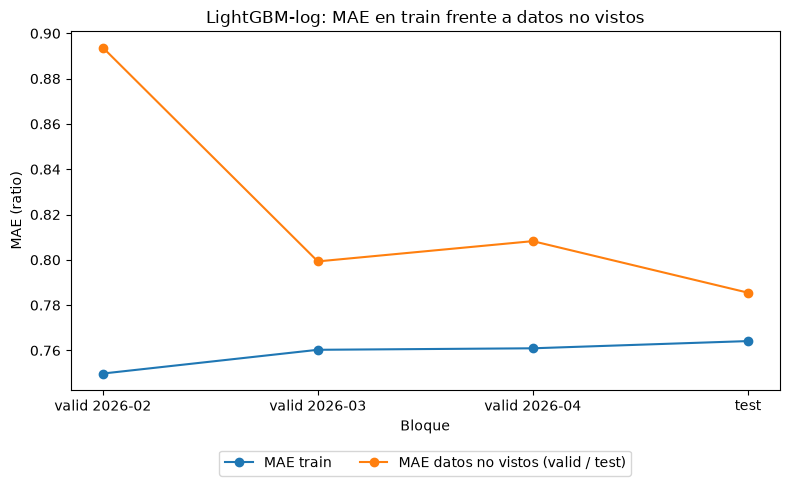

In [117]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sobreajuste["bloque"], sobreajuste["MAE_train"], marker="o", label="MAE train")
ax.plot(sobreajuste["bloque"], sobreajuste["MAE_eval"], marker="o", label="MAE datos no vistos (valid / test)")
ax.set_title("LightGBM-log: MAE en train frente a datos no vistos")
ax.set_xlabel("Bloque")
ax.set_ylabel("MAE (ratio)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
plt.tight_layout()
plt.savefig(FIGURES / "15_sobreajuste_lgbm_log.png", dpi=200, bbox_inches="tight")
plt.show()

## 9. Evolución mensual del error

Me interesa graficar la evolución del error mes a mes, para el conjunto total de los datos, con el modelo final
entrenado con todo desarrollo (el mismo que se evaluó en test).

> En los meses de desarrollo el modelo ya ha visto esas fases al entrenar, así que su error en esos meses es error de
> entrenamiento; solo los meses de test (desde mayo de 2026) son datos no vistos.

In [118]:
desarrollo = df_lgbm[df_lgbm["split"] == "desarrollo"]
modelo_final.fit(desarrollo[VARIABLES], np.log(desarrollo[OBJETIVO]))

# Error fase a fase en todos los meses
evolucion = df_lgbm[["mes_orden", OBJETIVO]].copy()
evolucion["pred"] = np.exp(modelo_final.predict(df_lgbm[VARIABLES]))
evolucion["err_modelo"] = (evolucion["pred"] - evolucion[OBJETIVO]).abs()
evolucion["err_B0"] = (1 - evolucion[OBJETIVO]).abs()

# MAE por mes = media del error absoluto de las fases de ese mes
mae_mensual = evolucion.groupby("mes_orden")[["err_modelo", "err_B0"]].mean()
display(mae_mensual.round(3))

print(f"Error mínimo del modelo: {mae_mensual['err_modelo'].min():.3f} (mes: {mae_mensual['err_modelo'].idxmin()})")
print(f"Error máximo del modelo: {mae_mensual['err_modelo'].max():.3f} (mes: {mae_mensual['err_modelo'].idxmax()})")

,err_modelo,err_B0
mes_orden,,
2025-06,0.746,0.988
2025-07,0.738,0.938
2025-08,0.675,0.842
2025-09,0.714,0.915
2025-10,0.734,0.995
2025-11,0.797,1.077
2025-12,0.877,1.196
2026-01,0.846,1.125
2026-02,0.815,1.140


Error mínimo del modelo: 0.675 (mes: 2025-08)
Error máximo del modelo: 0.877 (mes: 2025-12)


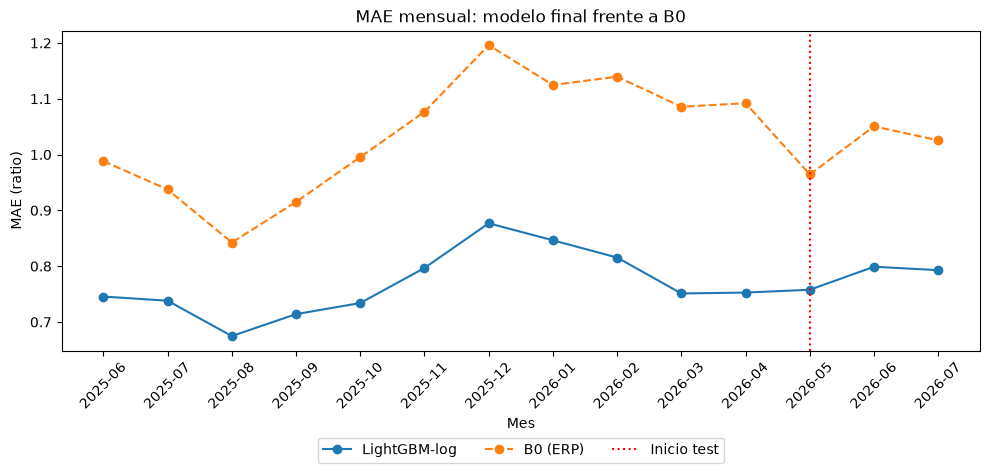

In [119]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(mae_mensual.index, mae_mensual["err_modelo"], marker="o", label="LightGBM-log")
ax.plot(mae_mensual.index, mae_mensual["err_B0"], marker="o", linestyle="--", label="B0 (ERP)")
ax.axvline("2026-05", color="red", linestyle=":", label="Inicio test")

ax.set_title("MAE mensual: modelo final frente a B0")
ax.set_xlabel("Mes")
ax.set_ylabel("MAE (ratio)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=3)
plt.tight_layout()
plt.savefig(FIGURES / "15_mae_mensual.png", dpi=200, bbox_inches="tight")
plt.show()

Este gráfico muestra tres cosas interesantes:

- El modelo tiene menos error que B0 en los 14 meses (en los de desarrollo, con datos que ya ha visto).
- La línea de B0 (naranja) marca los meses más difíciles de predecir, en los que el tiempo real se aleja más del
  tiempo previsto por el ERP. El tramo de noviembre a febrero es el más difícil, con el máximo en diciembre, y agosto
  el más fácil. El modelo sube y baja en los mismos meses que B0, lo que indica que la variación mensual de su error
  se debe sobre todo a la dificultad de cada mes y no a un comportamiento distinto del modelo.
- La línea roja marca el corte entre entrenamiento y test. En los meses de test el MAE del modelo (0,762–0,797) queda
  dentro del rango de los meses de entrenamiento (0,676–0,885) y muy cerca de los últimos meses de desarrollo. Que el
  error apenas suba al pasar a datos no vistos es un buen indicador de generalización.

## 10. Interpretabilidad (SHAP)

LightGBM funciona como una caja negra; SHAP ayuda a visualizar el peso de cada variable en el resultado de la
predicción.

Debe tenerse en cuenta que el modelo final trabaja con el log del ratio, no con el ratio: SHAP reparte la predicción
en escala log y eso debe convertirse. Se usa el modelo final entrenado con todo desarrollo y se explican las fases de
test.

In [120]:
test = df_lgbm[df_lgbm["split"] == "test"]

# Explicador para modelos de árboles (modelo_final está entrenado con todo desarrollo)
explainer = shap.TreeExplainer(modelo_final)
shap_values = explainer(test[VARIABLES])

print(shap_values.shape)                                                   # (fases de test, nº variables)
print(f"Valor base (log): {explainer.expected_value:.3f}")
print(f"Valor base (ratio): {np.exp(explainer.expected_value):.3f}")

(2385, 7)
Valor base (log): 0.420
Valor base (ratio): 1.522


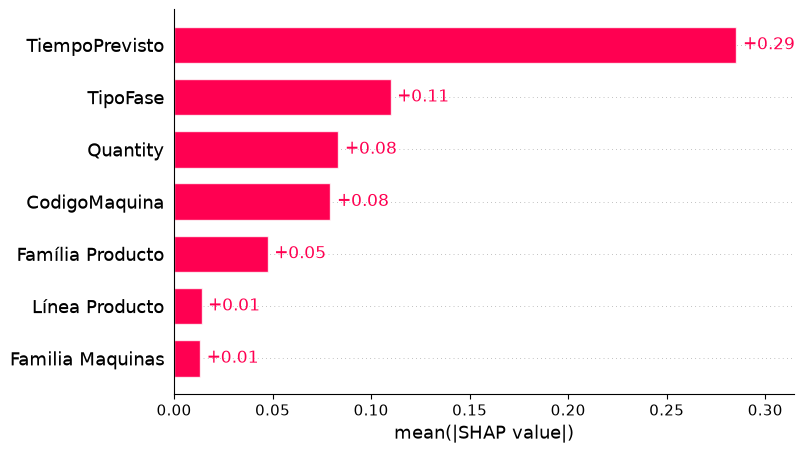

In [121]:
shap.plots.bar(shap_values, show=False)
plt.savefig(FIGURES / "15_shap_importancia.png", dpi=200, bbox_inches="tight")
plt.show()

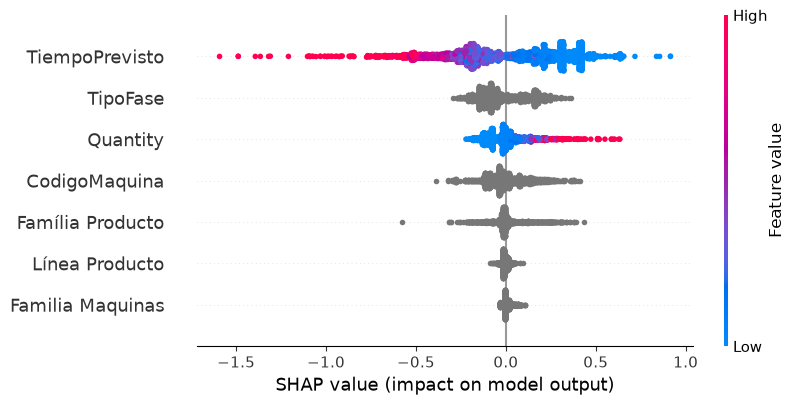

In [122]:
shap.plots.beeswarm(shap_values, show=False)
plt.savefig(FIGURES / "15_shap_beeswarm.png", dpi=200, bbox_inches="tight")
plt.show()

In [123]:
importancia = pd.Series(np.abs(shap_values.values).mean(axis=0), index=VARIABLES)
tabla_shap = (pd.DataFrame({"media_abs_SHAP": importancia,
                            "efecto_ratio_%": (np.exp(importancia) - 1) * 100})
              .sort_values("media_abs_SHAP", ascending=False))
tabla_shap.round(2).to_csv(TABLES / "shap_importancia.csv")
tabla_shap.round(2)

,media_abs_SHAP,efecto_ratio_%
TiempoPrevisto,0.29,33.03
TipoFase,0.11,11.61
Quantity,0.08,8.70
CodigoMaquina,0.08,8.26
Família Producto,0.05,4.86
Línea Producto,0.01,1.40
Familia Maquinas,0.01,1.33


### Interpretabilidad del modelo final (SHAP en test)

**Importancia global:** `TiempoPrevisto` obtiene el valor más alto (0,29), seguido de `TipoFase` (0,11), `Quantity`
(0,09) y `CodigoMaquina` (0,08). `Família Producto` obtiene 0,05, y `Familia Maquinas` y `Línea Producto`, 0,01.

**Dirección del efecto:**

- `TiempoPrevisto`: los valores bajos se asocian a valores SHAP positivos (aumentan el ratio inferido) y los valores
  altos a valores SHAP negativos (lo reducen).
- `Quantity`: los valores altos se asocian a valores SHAP positivos.
- `TipoFase`, `CodigoMaquina` y `Família Producto` presentan valores SHAP positivos y negativos.
- `Familia Maquinas` y `Línea Producto` presentan valores SHAP concentrados en torno a 0. La baja influencia de estas
  variables se explica por la estructura jerárquica de las mismas: cada máquina pertenece a una única familia y cada
  familia de producto a una única línea. Al conocer `CodigoMaquina` y `Família Producto`, el modelo dispone ya de la
  información de `Familia Maquinas` y `Línea Producto`, por lo que estas no aportan información adicional. Esto no
  implica que la familia de máquina o la línea de producto no estén relacionadas con la desviación, sino que su efecto
  queda recogido a través de las variables más detalladas.